In [1]:
from pydantic import BaseModel

# langraph - State, Nodes, Edges, LLM

# State object
class AgentState(BaseModel):
    question : str 
    answer : str = None

In [2]:
!Ollama list

NAME            ID              SIZE      MODIFIED   
llama3.2:3b     a80c4f17acd5    2.0 GB    3 days ago    
qwen3.5:0.8b    f3817196d142    1.0 GB    8 days ago    


In [3]:
from langchain_ollama import ChatOllama
llm = ChatOllama(model="llama3.2:3b")

# Create node
def Chatbot(state : AgentState):
    answer = llm.invoke(state.question)
    state.answer = answer.content
    return state

In [8]:
from langgraph.graph import StateGraph, END

# create graph
graphBuilder = StateGraph(AgentState)

# Add node to graph
graphBuilder.add_node("cnode", Chatbot)

# add edge to connect chatbot node to END node
graphBuilder.add_edge("cnode", END)

# set entry node
graphBuilder.set_entry_point("cnode")

# compile to create the graph 
graph = graphBuilder.compile()

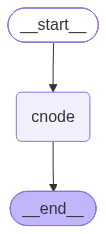

In [9]:
# Visualize the graph
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
state = AgentState(question = "Explain Tranformer")
answer = graph.invoke(state)
print(answer)

{'question': 'Explain Tranformer', 'answer': 'The Transformer!\n\nThe Transformer is a type of neural network architecture that has revolutionized the field of natural language processing (NLP) and computer vision. It was introduced in 2017 by Vaswani et al. in their paper "Attention is All You Need."\n\n**What problem does it solve?**\n\nTraditional recurrent neural networks (RNNs) have difficulty handling long-range dependencies between tokens or pixels due to the sequential nature of data. The Transformer architecture addresses this limitation by introducing self-attention mechanisms that allow the model to weigh the importance of different input elements relative to each other.\n\n**Key components:**\n\n1. **Self-Attention Mechanism:** This is the core component of the Transformer. It allows the model to attend to specific positions in the sequence and weigh their importance.\n2. **Multi-Head Attention:** The self-attention mechanism is applied multiple times, with different weight